# RAG multimodal et agentique sur « Attention Is All You Need »

**Chaîne :** PDF → PyMuPDF → textes + images → CLIP → ChromaDB → outil de recherche → agent ReAct (LangGraph).

| Rôle | Modèle (local) |
|---|---|
| Espace commun texte et image | CLIP `ViT-B-32` (`open_clip`) |
| Recherche précise dans le texte | `mxbai-embed-large` via Ollama |
| Raisonnement de l'agent (MIND) | `qwen3:8b` via Ollama |
| Lecture des figures | `qwen2.5vl:3b` via Ollama |

Prérequis : Ollama lancé, avec les trois modèles téléchargés.

In [1]:
import base64, hashlib, io, re
from pathlib import Path

import chromadb, open_clip, pymupdf, torch
from IPython.display import Image as ImageIPython, Markdown, display
from PIL import Image
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

PDF_PATH = Path("pdfs/attention is all you need.pdf")
SORTIE = Path("resultats_pdf")
TEXT_DIR, IMAGE_DIR = SORTIE / "textes", SORTIE / "images"
for dossier in (TEXT_DIR, IMAGE_DIR):
    dossier.mkdir(parents=True, exist_ok=True)

**Interprétation.** La cellule charge les bibliothèques et crée l'arborescence `resultats_pdf/textes` et `resultats_pdf/images`. Chaque outil a un rôle précis : PyMuPDF pour l'extraction, `open_clip` pour les embeddings, ChromaDB pour le stockage, LangChain et LangGraph pour l'agent. Les chemins sont centralisés, ce qui facilite le changement de document.

## Étape 1 : extraction des textes et des images

Un fichier texte par page, plus `texte_complet.txt`. Les figures de ce PDF utilisent un **masque de transparence** (`smask`) : il faut le recombiner avec l'image, puis poser le résultat sur un fond blanc.

11 pages, 3 images

page_003_image_94.png
  Figure 1: The Transformer - model architecture.


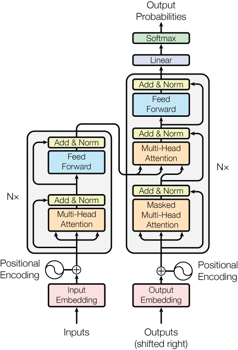


page_004_image_102.png
  Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel. [This image is the right part of the figure.]


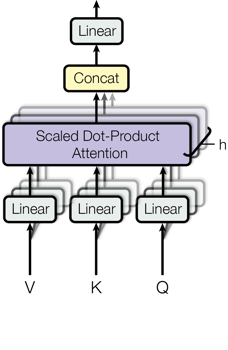


page_004_image_104.png
  Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel. [This image is the left part of the figure.]


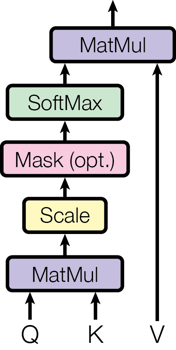

In [2]:
def extraire_image(doc, xref, smask):
    pix = pymupdf.Pixmap(doc, xref)
    if smask:
        pix = pymupdf.Pixmap(pix, pymupdf.Pixmap(doc, smask))
    image = Image.open(io.BytesIO(pix.tobytes("png"))).convert("RGBA")
    fond = Image.new("RGBA", image.size, "white")
    fond.alpha_composite(image)
    return fond.convert("RGB")

# Nettoyer les sorties d'une extraction précédente
for ancien in [*TEXT_DIR.glob("page_*.txt"), *IMAGE_DIR.glob("page_*.png")]:
    ancien.unlink()

textes_pages, legendes = [], {}
with pymupdf.open(PDF_PATH) as doc:
    for numero, page in enumerate(doc, start=1):
        texte = page.get_text(sort=True)  # conserve les lignes et colonnes des tableaux
        textes_pages.append(texte)
        (TEXT_DIR / f"page_{numero:03d}.txt").write_text(texte, encoding="utf-8")
        # Légendes "Figure N: ..." de la page
        legende = " ".join(
            " ".join(bloc[4].split()) for bloc in page.get_text("blocks")
            if re.match(r"Figure \d+:", bloc[4].strip())
        )
        images_page = page.get_images(full=True)
        # De gauche à droite, pour distinguer les figures qui partagent une légende
        images_page.sort(key=lambda infos: page.get_image_rects(infos[0])[0].x0)
        for rang, infos in enumerate(images_page):
            xref, smask = infos[0], infos[1]
            nom = f"page_{numero:03d}_image_{xref}.png"
            extraire_image(doc, xref, smask).save(IMAGE_DIR / nom)
            position = ""
            if len(images_page) == 2:
                position = f" [This image is the {('left', 'right')[rang]} part of the figure.]"
            legendes[nom] = legende + position

(SORTIE / "texte_complet.txt").write_text("\n\n".join(textes_pages), encoding="utf-8")
print(f"{len(textes_pages)} pages, {len(legendes)} images")
for nom, legende in sorted(legendes.items()):
    print(f"\n{nom}\n  {legende}")
    apercu = Image.open(IMAGE_DIR / nom)
    apercu.thumbnail((350, 350))
    display(apercu)

**Interprétation.** L'extraction produit **11 pages** et **3 images** : l'architecture du Transformer (p. 3) et les deux parties de la figure 2 (p. 4). La recomposition avec le masque de transparence donne des figures sur fond blanc. Les deux images de la page 4 partagent la même légende : la mention *left* / *right*, déduite de leur position dans la page, permet de les distinguer. Ce détail est important pour que l'agent ne les confonde pas.

## Étape 2 : embeddings CLIP dans un espace latent commun

CLIP encode le texte et les images en vecteurs de même dimension. Les vecteurs sont **normalisés**, donc le produit scalaire est égal à la similarité cosinus. Chaque image est complétée en carré, sinon le prétraitement de CLIP en coupe les bords.

In [3]:
NOM_MODELE, POIDS = "ViT-B-32", "laion2b_s34b_b79k"
modele_clip, _, pretraitement = open_clip.create_model_and_transforms(NOM_MODELE, pretrained=POIDS)
modele_clip.eval()
tokeniseur = open_clip.get_tokenizer(NOM_MODELE)

def normaliser(v):
    return v / v.norm(dim=-1, keepdim=True)

@torch.inference_mode()
def encoder_textes(textes):
    return normaliser(modele_clip.encode_text(tokeniseur(textes))).tolist()

def en_carre(image):
    cote = max(image.size)
    carre = Image.new("RGB", (cote, cote), "white")
    carre.paste(image, ((cote - image.width) // 2, (cote - image.height) // 2))
    return carre

@torch.inference_mode()
def encoder_image(chemin):
    with Image.open(chemin) as image:
        tenseur = pretraitement(en_carre(image.convert("RGB"))).unsqueeze(0)
    return normaliser(modele_clip.encode_image(tenseur))[0].tolist()

**Interprétation.** CLIP `ViT-B-32` dispose de deux encodeurs, un pour le texte et un pour l'image, qui projettent dans un **même espace vectoriel**. Après normalisation L2, chaque vecteur a une norme de 1 : le produit scalaire est alors égal à la similarité cosinus. La mise au carré évite que le recadrage central ne supprime une partie des figures, notamment celles en hauteur. La cellule ne produit pas d'affichage : elle définit les fonctions utilisées ensuite.

### Découpage du texte

CLIP ne lit que **77 tokens** (dont 2 réservés). La longueur des fragments est donc mesurée en tokens CLIP ; au-delà, le texte serait tronqué sans avertissement.

In [4]:
def nb_tokens(texte):
    return len(open_clip.tokenizer._tokenizer.encode(texte))

decoupeur = RecursiveCharacterTextSplitter(
    chunk_size=70, chunk_overlap=15, length_function=nb_tokens,
    separators=["\n\n", ". ", "\n", " ", ""], keep_separator="end",
)
exemples = decoupeur.split_text(textes_pages[3])
print(len(exemples), "fragments page 4 ; maximum :", max(map(nb_tokens, exemples)), "tokens")

12 fragments page 4 ; maximum : 65 tokens


**Interprétation.** La page 4 est découpée en **12 fragments**, dont le plus long compte **65 tokens**, sous la limite fixée à 70. Sur cet exemple, la contrainte de CLIP (77 tokens) est respectée. Le chevauchement, jusqu'à 15 tokens, limite la perte de contexte entre deux fragments. En contrepartie, des fragments aussi courts portent peu de contexte.

## Étape 3 : indexation dans ChromaDB

`document_id` est l'empreinte **SHA-256** du PDF. Avant d'indexer, les entrées du même fichier sont supprimées, y compris celles d'une ancienne version : relancer la cellule ne crée pas de doublons.

In [5]:
client = chromadb.PersistentClient(path="chroma_db")
collection = client.get_or_create_collection("rag_multimodal", metadata={"hnsw:space": "cosine"})

def indexer():
    document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
    collection.delete(where={"pdf": PDF_PATH.name})

    ids, documents, metadatas = [], [], []
    for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
        page = int(fichier.stem.split("_")[1])
        for i, fragment in enumerate(decoupeur.split_text(fichier.read_text(encoding="utf-8"))):
            ids.append(f"{document_id}:texte:{page}:{i}")
            documents.append(fragment)
            metadatas.append({"type": "texte", "document_id": document_id, "pdf": PDF_PATH.name,
                              "page": page, "fragment": i, "source": str(fichier)})
    for debut in range(0, len(ids), 64):
        lot = slice(debut, debut + 64)
        collection.upsert(ids=ids[lot], documents=documents[lot], metadatas=metadatas[lot],
                          embeddings=encoder_textes(documents[lot]))

    for fichier in sorted(IMAGE_DIR.glob("page_*.png")):
        collection.upsert(
            ids=[f"{document_id}:image:{fichier.name}"],
            embeddings=[encoder_image(fichier)],  # calculé à partir des pixels
            documents=[legendes.get(fichier.name) or f"Image extraite : {fichier.name}"],
            metadatas=[{"type": "image", "document_id": document_id, "pdf": PDF_PATH.name,
                        "page": int(fichier.stem.split("_")[1]), "chemin_image": str(fichier),
                        "source": str(fichier)}])
    return document_id

document_id = indexer()
total = collection.count()
indexer()
assert collection.count() == total, "La réindexation a créé des doublons"
print("document_id :", document_id)
for t in ("texte", "image"):
    print(t, ":", len(collection.get(where={"type": t})["ids"]))

document_id : d87d482d5ae7960e2e43d7dd6d21377e60e73e8fce1bf2a01aff7aca8a08c537
texte : 182
image : 3


**Interprétation.** La base contient **182 fragments de texte** et **3 images**. L'identifiant SHA-256 dépend du contenu du PDF et non de son nom. L'indexation est lancée deux fois et l'assertion vérifie que le nombre d'éléments reste le même : la **réindexation ne crée donc pas de doublons**. Les métadonnées (type, page, chemin de l'image) permettent de filtrer les résultats et de citer les sources.

## Étape 4 : recherche multimodale

La requête est un **texte** ou une **image**. Similarité = 1 − distance cosinus.

Avec CLIP, les scores texte-texte sont nettement plus élevés que les scores texte-image. Un classement mélangé écarterait presque toujours les images : on cherche donc les `k` meilleurs résultats **par type**. Ce modèle CLIP comprend surtout l'anglais.

In [6]:
def rechercher(texte=None, image=None, type_resultat=None, k=3):
    """Retourne les k meilleurs résultats de chaque type demandé."""
    if (texte is None) == (image is None):
        raise ValueError("Fournir soit un texte, soit une image.")
    if type_resultat not in (None, "texte", "image") or k < 1:
        raise ValueError("type_resultat : 'texte', 'image' ou None ; k >= 1.")
    vecteur = encoder_textes([texte])[0] if texte is not None else encoder_image(image)

    resultats = []
    for t in ([type_resultat] if type_resultat else ["texte", "image"]):
        r = collection.query(query_embeddings=[vecteur], n_results=k, where={"type": t},
                             include=["documents", "metadatas", "distances"])
        resultats += [{**m, "contenu": d, "score": 1 - dist}
                      for d, m, dist in zip(r["documents"][0], r["metadatas"][0], r["distances"][0])]
    return resultats

def afficher_resultats(resultats):
    for r in resultats:
        print(f"\n{r['type'].upper()} | page {r['page']} | similarité cosinus {r['score']:.3f}")
        print(r["contenu"])
        if r["type"] == "image":
            apercu = Image.open(r["chemin_image"])
            apercu.thumbnail((350, 350))
            display(apercu)

**Interprétation.** La fonction `rechercher` accepte **soit un texte, soit une image** et interroge la collection par similarité cosinus. La recherche est effectuée séparément pour chaque type : les scores texte-texte et texte-image n'ont pas la même échelle, et un classement unique risquerait d'écarter les images. `afficher_resultats` présente le texte ou l'aperçu de l'image.

**Requête texte → textes et images**


TEXTE | page 3 | similarité cosinus 0.653
3.2  Attention

TEXTE | page 3 | similarité cosinus 0.651
3.2.1  Scaled Dot-Product Attention

We call our particular attention "Scaled Dot-Product Attention" (Figure 2). The input consists of
queries and keys of dimension dk, and values of dimension dv. We compute the dot products of the


                                       3

IMAGE | page 4 | similarité cosinus 0.314
Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel. [This image is the right part of the figure.]


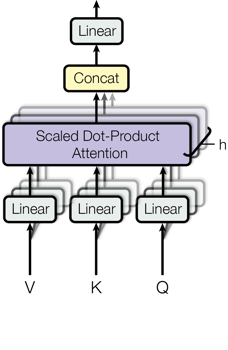


IMAGE | page 4 | similarité cosinus 0.212
Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel. [This image is the left part of the figure.]


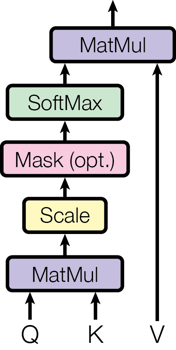

In [7]:
afficher_resultats(rechercher(texte="scaled dot-product attention", k=2))

**Interprétation.** Les deux passages retrouvés (p. 3, scores d'environ **0,65**) sont bien situés dans la section sur l'attention : le premier est un simple titre, le second introduit le *Scaled Dot-Product Attention*. Les figures obtiennent des scores plus faibles (**0,31** et **0,21**), ce qui justifie la recherche séparée par type.

**Point critique :** CLIP classe en premier la partie droite de la figure 2 (*Multi-Head*), alors que la requête vise la partie gauche. Il retrouve la bonne zone du document, mais distingue mal deux schémas proches.

**Requête image → textes et images** (la figure de la page 3 doit se retrouver elle-même avec un score proche de 1)


TEXTE | page 5 | similarité cosinus 0.313
3.3  Position-wise Feed-Forward Networks

In addition to attention sub-layers, each of the layers in our encoder and decoder contains a fully
connected feed-forward network, which is applied to each position separately and identically. This
consists of two linear transformations with a ReLU activation in between.

TEXTE | page 3 | similarité cosinus 0.312
Similar to the encoder, we employ residual connections
around each of the sub-layers, followed by layer normalization. We also modify the self-attention
sub-layer in the decoder stack to prevent positions from attending to subsequent positions.

IMAGE | page 3 | similarité cosinus 1.000
Figure 1: The Transformer - model architecture.


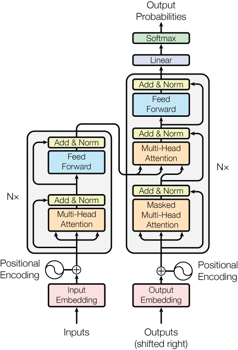


IMAGE | page 4 | similarité cosinus 0.773
Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel. [This image is the left part of the figure.]


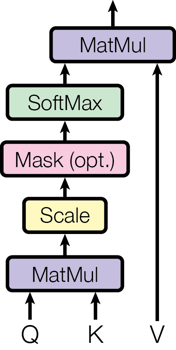

In [8]:
afficher_resultats(rechercher(image=next(IMAGE_DIR.glob("page_003_*.png")), k=2))

**Interprétation.** La figure de la page 3 se retrouve elle-même avec un score de **1,000**, ce qui valide la cohérence de l'encodage et de l'indexation des images. La seconde image obtient **0,773** : les deux sont des schémas liés à l'attention. Les passages de texte ont des scores proches de **0,31** et un lien assez général avec la figure. La recherche image → image est ici nettement plus discriminante que la recherche image → texte.

### Recherche précise dans le texte

CLIP est entraîné à associer des images à des légendes courtes : pour retrouver un passage précis d'un article, il est limité. Un **second index**, réservé au texte, utilise `mxbai-embed-large` avec des fragments plus longs.

L'espace commun CLIP reste utilisé pour les figures et les requêtes par image. Les scores des deux modèles ne sont **pas comparables** entre eux.

In [9]:
embeddings_texte = OllamaEmbeddings(model="mxbai-embed-large")
PREFIXE_REQUETE = "Represent this sentence for searching relevant passages: "  # recommandé pour ce modèle
decoupeur_long = RecursiveCharacterTextSplitter(
    chunk_size=1200, chunk_overlap=200,
    separators=["\n\n", ". ", "\n", " ", ""], keep_separator="end")
collection_texte = client.get_or_create_collection("rag_texte", metadata={"hnsw:space": "cosine"})

def indexer_texte():
    collection_texte.delete(where={"pdf": PDF_PATH.name})
    ids, documents, metadatas = [], [], []
    for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
        page = int(fichier.stem.split("_")[1])
        for i, fragment in enumerate(decoupeur_long.split_text(fichier.read_text(encoding="utf-8"))):
            ids.append(f"{document_id}:{page}:{i}")
            documents.append(fragment)
            metadatas.append({"type": "texte", "document_id": document_id, "pdf": PDF_PATH.name,
                              "page": page, "fragment": i, "source": str(fichier)})
    collection_texte.upsert(ids=ids, documents=documents, metadatas=metadatas,
                            embeddings=embeddings_texte.embed_documents(documents))
    return len(ids)

def rechercher_texte(requete, k=4):
    vecteur = embeddings_texte.embed_query(PREFIXE_REQUETE + requete)
    r = collection_texte.query(query_embeddings=[vecteur], n_results=k,
                               include=["documents", "metadatas", "distances"])
    return [{**m, "contenu": d, "score": 1 - dist}
            for d, m, dist in zip(r["documents"][0], r["metadatas"][0], r["distances"][0])]

print(indexer_texte(), "fragments longs indexés")

46 fragments longs indexés


**Interprétation.** Un second index de **46 fragments** (jusqu'à 1 200 caractères) est construit avec `mxbai-embed-large`. Les fragments, plus longs que ceux de CLIP, conservent davantage de contexte. Cet index **complète** l'espace commun CLIP sans le remplacer : CLIP reste utilisé pour les figures et les requêtes par image.

### Comparaison mesurée

Pour 12 questions, on cherche le rang du premier fragment qui contient la réponse attendue. La mesure porte sur ce seul article et ces seules questions.

In [10]:
QUESTIONS_TEST = [
    ("number of attention heads in base model", r"h = 8"),
    ("BLEU score English-to-German base model", r"27\.3"),
    ("optimizer used for training", r"Adam optimizer"),
    ("dropout rate of the base model", r"Pdrop = 0\.1"),
    ("dimension of the model dmodel", r"dmodel = 512"),
    ("inner-layer dimensionality of feed-forward network", r"2048"),
    ("number of identical layers in the encoder", r"stack of N = 6"),
    ("hardware used for training, number of GPUs", r"8 NVIDIA P100"),
    ("warmup steps learning rate schedule", r"4000"),
    ("label smoothing value", r"ls = 0\.1"),
    ("positional encoding formula sine cosine", r"sine and cosine functions"),
    ("why scale the dot products by square root of dk", r"extremely small"),
]

def rang(resultats, motif):
    return next((n for n, r in enumerate(resultats, 1) if re.search(motif, r["contenu"])), None)

top5 = {"CLIP": 0, "mxbai": 0}
print(f"{'question':55s} CLIP  mxbai   (rang)")
for question, motif in QUESTIONS_TEST:
    rangs = {
        "CLIP": rang(rechercher(texte=question, type_resultat="texte", k=collection.count()), motif),
        "mxbai": rang(rechercher_texte(question, k=collection_texte.count()), motif),
    }
    for nom, valeur in rangs.items():
        top5[nom] += valeur is not None and valeur <= 5
    print(f"{question:55s} {str(rangs['CLIP']):5s} {rangs['mxbai']}")
print("Bonne réponse dans les 5 premiers :", top5, "sur", len(QUESTIONS_TEST))

question                                                CLIP  mxbai   (rang)
number of attention heads in base model                 6     2
BLEU score English-to-German base model                 7     1
optimizer used for training                             1     1


dropout rate of the base model                          1     1
dimension of the model dmodel                           3     2
inner-layer dimensionality of feed-forward network      5     1
number of identical layers in the encoder               2     2


hardware used for training, number of GPUs              6     1
warmup steps learning rate schedule                     4     1
label smoothing value                                   1     1
positional encoding formula sine cosine                 2     3


why scale the dot products by square root of dk         2     2
Bonne réponse dans les 5 premiers : {'CLIP': 9, 'mxbai': 12} sur 12


**Interprétation.** La réponse attendue figure dans les 5 premiers résultats pour **12 questions sur 12 avec `mxbai`**, contre **9 sur 12 avec CLIP**. L'écart est visible sur le nombre de têtes (rang 2 contre 6), le score BLEU (1 contre 7) et le matériel (1 contre 6). `mxbai` n'est pas meilleur partout : sur l'encodage positionnel, CLIP est mieux classé (2 contre 3).

Cette mesure justifie l'usage de `mxbai` pour le texte. Sa portée reste limitée : un seul document, 12 questions, et deux index découpés différemment. Elle compare donc deux **chaînes de recherche**, et pas uniquement deux modèles.

## Étape 5 : le retriever devient un outil

La docstring est la **description** que lit le LLM pour savoir quand et comment appeler l'outil. Il accepte **une requête par sous-question**. Le texte vient de l'index `mxbai`, les figures de CLIP. L'outil renvoie un texte (l'observation) et un *artefact* contenant les résultats bruts, qui permet d'afficher les figures.

`qwen3:8b` ne voit pas les images : les figures retrouvées sont lues par `qwen2.5vl:3b`. Ce petit modèle peut inventer des liens entre les blocs. On lui demande donc seulement les éléments visibles, et la **légende du PDF** est fournie comme source fiable.

In [11]:
vlm = ChatOllama(model="qwen2.5vl:3b", temperature=0, num_predict=300, repeat_penalty=1.15)
cache_descriptions = {}

def decrire_image(chemin):
    if chemin not in cache_descriptions:
        with Image.open(chemin) as image:
            image = image.convert("RGB")
        image.thumbnail((1024, 1024))
        tampon = io.BytesIO()
        image.save(tampon, "PNG")
        url = "data:image/png;base64," + base64.b64encode(tampon.getvalue()).decode()
        cache_descriptions[chemin] = vlm.invoke([HumanMessage(content=[
            {"type": "text", "text": "List the text labels you can read in this figure, each once. "
                                     "Do not describe connections. Do not guess."},
            {"type": "image_url", "image_url": url}])]).content
    return cache_descriptions[chemin]

@tool(response_format="content_and_artifact")
def retriever_tool(requetes: list[str], chemin_image: str = "", type_resultat: str = "tous"):
    """Search the indexed PDF "Attention Is All You Need" (Transformer architecture, attention,
    positional encoding, training, results). Returns text passages and figures with page numbers.
    Call it before answering any question about the paper; call it again with other queries
    if the observation is not sufficient.

    Args:
        requetes: short search queries IN ENGLISH, ONE PER SUB-QUESTION. A question asking
            two things needs two queries. Each query must be self-contained: keep the precise
            qualifiers of the question (which model variant, language pair, dataset).
        chemin_image: path of a query image, only if the user gave one.
        type_resultat: "texte", "image" or "tous".
    """
    requetes = [q.strip() for q in requetes if q.strip()][:4]
    # Le LLM place parfois le chemin de l'image dans les requêtes, voire le déforme
    nom_image = re.search(r"page_\d+_image_\d+\.png", " ".join([chemin_image, *requetes]))
    if nom_image:
        chemin_image, type_resultat = str(IMAGE_DIR / nom_image.group()), "tous"
    if not chemin_image and not requetes:
        return "Search error: give at least one query.", []

    blocs, resultats, deja_vus = [], [], set()

    def ajouter(r):
        cle = r.get("chemin_image") or (r["page"], r["fragment"])
        if cle in deja_vus:
            return
        deja_vus.add(cle)
        resultats.append(r)
        if r["type"] == "texte":
            blocs.append(f"[TEXT from page {r['page']}]\n{r['contenu']}\n[end of passage, cite it as (p. {r['page']})]")
        else:
            blocs.append(f"[FIGURE from page {r['page']}, file {r['chemin_image']}, score {r['score']:.2f}]\n"
                         f"Caption from the PDF (reliable): {r['contenu']}\n"
                         f"Labels read by a vision model (may contain errors): "
                         f"{decrire_image(r['chemin_image'])}")

    try:
        if chemin_image:
            # CLIP identifie la figure ; sa légende sert ensuite à chercher le texte
            figures = rechercher(image=chemin_image, type_resultat="image", k=2)
            if figures[0]["score"] > 0.95:  # image issue du document
                figures = figures[:1]
                textes = rechercher_texte(figures[0]["contenu"])
            else:
                textes = rechercher(image=chemin_image, type_resultat="texte", k=4)
            for r in figures + textes:
                ajouter(r)
        else:
            for requete in requetes:
                blocs.append(f"=== Results for query: {requete} ===")
                if type_resultat != "image":
                    for r in rechercher_texte(requete):
                        ajouter(r)
                if type_resultat != "texte" and requete == requetes[0]:
                    for r in rechercher(texte=requete, type_resultat="image", k=2):
                        ajouter(r)
    except (ValueError, OSError) as erreur:
        return f"Search error: {erreur}", []
    return "\n\n".join(blocs), resultats

print(retriever_tool.name)
print(retriever_tool.description)
print(retriever_tool.args)

retriever_tool
Search the indexed PDF "Attention Is All You Need" (Transformer architecture, attention,
    positional encoding, training, results). Returns text passages and figures with page numbers.
    Call it before answering any question about the paper; call it again with other queries
    if the observation is not sufficient.

    Args:
        requetes: short search queries IN ENGLISH, ONE PER SUB-QUESTION. A question asking
            two things needs two queries. Each query must be self-contained: keep the precise
            qualifiers of the question (which model variant, language pair, dataset).
        chemin_image: path of a query image, only if the user gave one.
        type_resultat: "texte", "image" or "tous".
{'requetes': {'items': {'type': 'string'}, 'title': 'Requetes', 'type': 'array'}, 'chemin_image': {'default': '', 'title': 'Chemin Image', 'type': 'string'}, 'type_resultat': {'default': 'tous', 'title': 'Type Resultat', 'type': 'string'}}


**Interprétation.** La recherche devient l'outil `retriever_tool`. L'affichage montre les trois éléments transmis au LLM : le **nom**, la **description** et le **schéma des arguments**. La description demande des requêtes en anglais, une par sous-question. L'outil renvoie un texte pour le raisonnement et un *artefact* qui garde les résultats bruts pour l'affichage. Il comporte aussi une protection : si le LLM place mal ou déforme un nom d'image du document, le code le corrige.

## Étape 6 : agent ReAct avec LangGraph

- **MIND** : le LLM raisonne et décide d'appeler l'outil ou de répondre.
- **BODY** : le nœud `tools` exécute `retriever_tool`.
- **Cycle** : raisonnement → action (appel d'outil) → observation (`ToolMessage`) → raisonnement, jusqu'à la réponse finale.

In [12]:
outils = [retriever_tool]
llm = ChatOllama(model="qwen3:8b", temperature=0, reasoning=False, num_ctx=16384).bind_tools(outils)

CONSIGNES = SystemMessage(content="""You are a research agent answering questions about one PDF.
- For any question about the paper, call retriever_tool first, with an English query.
- If the user gives an image path, pass it in chemin_image.
- If the observation is insufficient, search again with a different query (3 searches at most).
- If the question has several parts, give one query per part in requetes.
- Every number and page you state must appear literally in an observation, with the page of the passage that contains it.
- The paper reports several model variants: use the table row of the variant the user asks about. A summary sentence may refer to another variant.
- Answer only from the observations and cite pages like (p. 4). If the information is not there, say so.
- If the question is unrelated to the paper, answer without calling the tool and say it is outside the document.
- Always answer in French.""")

def raisonnement(etat: MessagesState):
    return {"messages": [llm.invoke([CONSIGNES, *etat["messages"]])]}

graphe = StateGraph(MessagesState)
graphe.add_node("agent", raisonnement)
graphe.add_node("tools", ToolNode(outils))
graphe.add_edge(START, "agent")
graphe.add_conditional_edges("agent", tools_condition)  # tools, ou fin
graphe.add_edge("tools", "agent")
agent = graphe.compile()
print(agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools<hr/><small><em>__tools = retriever_tool</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> tools;
	tools --> agent;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**Interprétation.** Le diagramme généré (syntaxe Mermaid) confirme la structure du graphe :

```
START → agent ──(appel d'outil)──→ tools
          │  ↑                       │
          │  └────── observation ────┘
          └──(réponse finale)──→ END
```

Le nœud `agent` est le **MIND** et le nœud `tools` le **BODY**. La boucle entre les deux réalise le cycle **ReAct**. L'arête conditionnelle laisse le LLM décider : appeler l'outil ou terminer.

## Étape 7 : tests et validation

La trace montre chaque décision de l'agent : appels d'outil, observations, figures récupérées et réponse finale.

In [13]:
def interroger(question):
    print("QUESTION :", question)
    appels, figures, reponse = [], {}, ""
    for etape in agent.stream({"messages": [HumanMessage(content=question)]},
                              {"recursion_limit": 12}, stream_mode="updates"):
        for maj in etape.values():
            for message in maj["messages"]:
                if isinstance(message, AIMessage) and message.tool_calls:
                    for appel in message.tool_calls:
                        appels.append(appel["args"])
                        print("\n→ ACTION :", appel["name"], appel["args"])
                elif isinstance(message, ToolMessage):
                    sources = message.artifact or []
                    print("← OBSERVATION :", ", ".join(
                        f"{r['type']} p.{r['page']} ({r['score']:.2f})" for r in sources) or message.content)
                    figures.update({r["chemin_image"]: r["page"] for r in sources if r["type"] == "image"})
                else:
                    reponse = message.content
    print(f"\nRÉPONSE ({len(appels)} appel(s) d'outil) :")
    display(Markdown(reponse))
    for chemin, page in figures.items():
        print(f"Figure récupérée, page {page} : {chemin}")
        display(ImageIPython(filename=chemin, width=300))
    return {"appels": appels, "figures": list(figures), "reponse": reponse}

**Interprétation.** La fonction `interroger` exécute le graphe étape par étape et affiche les **actions**, les **observations** et la **réponse finale**. Cette trace rend le comportement de l'agent vérifiable. La limite de récursion (12) empêche une boucle sans fin.

**Test 1 : recherche hybride texte et figure**

QUESTION : Comment fonctionne le Scaled Dot-Product Attention ? Appuie-toi sur le texte et sur la figure.



→ ACTION : retriever_tool {'type_resultat': 'tous', 'requetes': ['How does the Scaled Dot-Product Attention work?']}


← OBSERVATION : texte p.3 (0.87), texte p.4 (0.81), texte p.4 (0.80), texte p.5 (0.76), image p.4 (0.33), image p.4 (0.24)



RÉPONSE (1 appel(s) d'outil) :


Le Scaled Dot-Product Attention fonctionne en calculant le produit scalaire entre les requêtes (queries) et les clés (keys), puis en appliquant une fonction softmax pour obtenir les poids qui seront utilisés pour combiner les valeurs (values). Plus précisément, chaque requête est multipliée par toutes les clés, et chaque produit scalaire est divisé par √dk pour éviter que les valeurs ne deviennent trop grandes, ce qui pourrait rendre la fonction softmax inefficace (p. 4).

La formule utilisée est la suivante :
$$
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{dk}}\right)V
$$
(p. 4).

La figure 2 (partie gauche) illustre ce mécanisme, avec des étiquettes comme "MatMul" (multiplication matricielle), "SoftMax" (fonction softmax), "Mask (opt.)" (masque optionnel) et "Scale" (échelle) qui correspondent aux étapes du calcul (p. 4).

Figure récupérée, page 4 : resultats_pdf/images/page_004_image_102.png


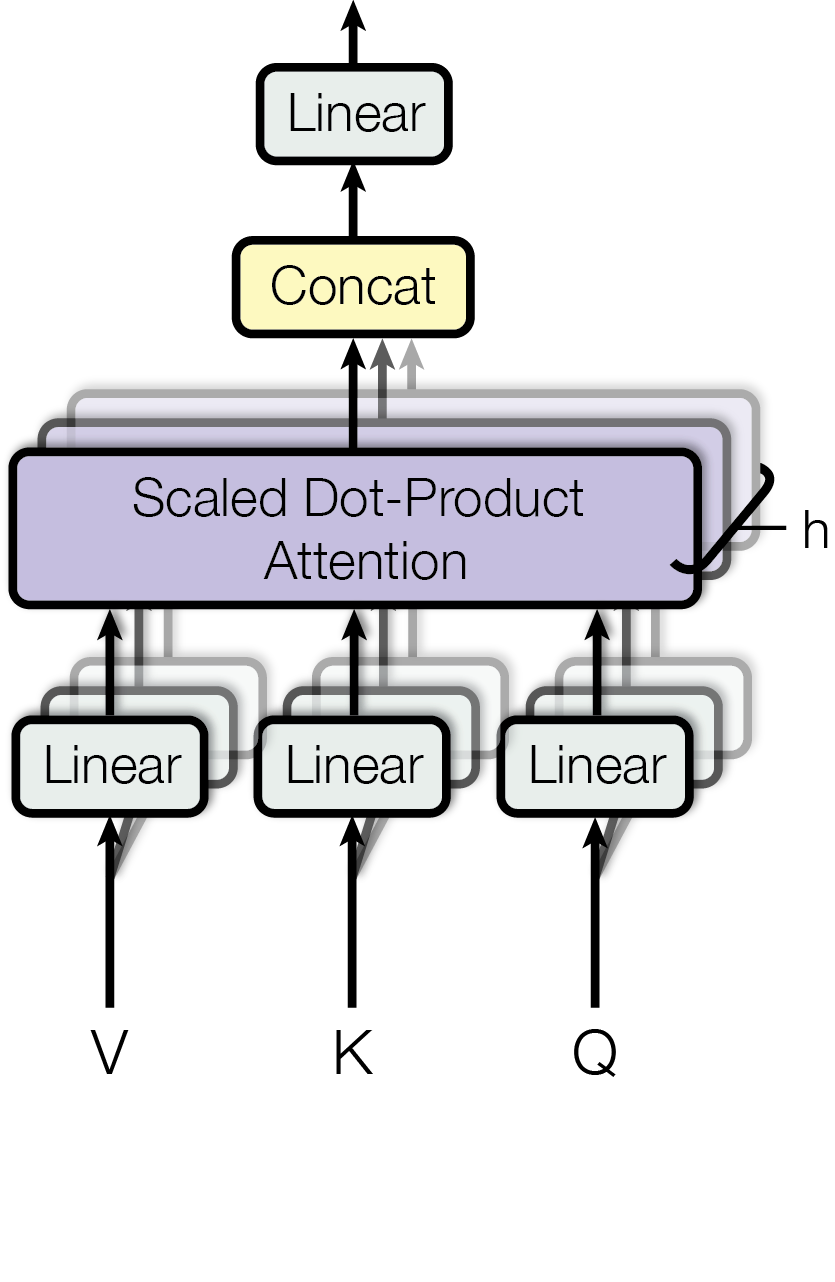

Figure récupérée, page 4 : resultats_pdf/images/page_004_image_104.png


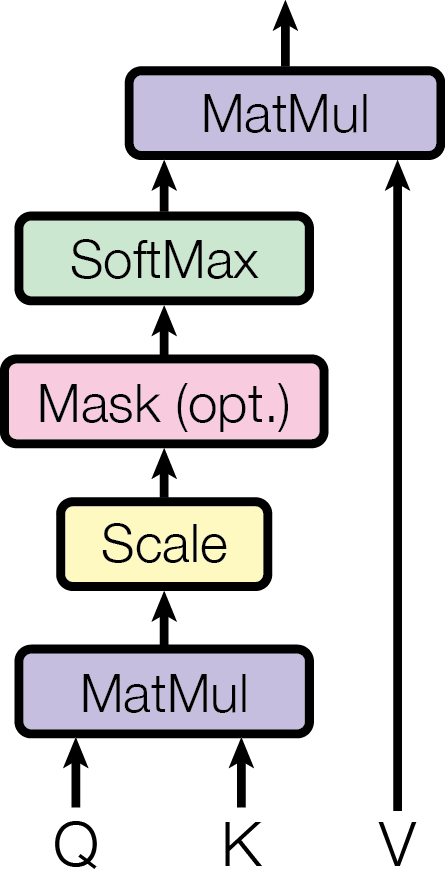

In [14]:
r1 = interroger("Comment fonctionne le Scaled Dot-Product Attention ? Appuie-toi sur le texte et sur la figure.")

**Interprétation.** L'agent appelle l'outil **une fois**, avec une requête reformulée en anglais. Il obtient 4 passages de texte et les 2 parties de la figure 2 : la recherche est bien **hybride**. La réponse présente le produit scalaire, la division par √dk, le softmax et la pondération des valeurs, avec la formule attendue. Les étiquettes de la figure citées (*MatMul*, *Scale*, *Mask*, *SoftMax*) correspondent au schéma de gauche.

**Test 2 : requête avec une image**

QUESTION : Que représente l'image resultats_pdf/images/page_004_image_104.png et quel est son rôle dans le Transformer ?



→ ACTION : retriever_tool {'requetes': ['What does the image results_pdf/images/page_004_image_104.png represent and what is its role in the Transformer?'], 'type_resultat': 'image'}


← OBSERVATION : image p.4 (1.00), texte p.4 (0.86), texte p.4 (0.84), texte p.5 (0.83), texte p.3 (0.82)



RÉPONSE (1 appel(s) d'outil) :


L'image **resultats_pdf/images/page_004_image_104.png** représente la **Scaled Dot-Product Attention** (Attention par produit scalaire échelonné), qui est une composante clé du mécanisme d'attention dans le modèle Transformer (p. 4). 

Son rôle dans le Transformer est de calculer les poids d'attention en effectuant le produit scalaire entre les vecteurs de requête (queries) et de clés (keys), puis de normaliser ces poids avec la fonction softmax pour obtenir des poids de distribution (p. 4). Ce processus permet au modèle de pondérer les valeurs (values) en fonction de leur pertinence par rapport aux requêtes, ce qui est essentiel pour la capture des relations entre les mots dans une séquence.

Figure récupérée, page 4 : resultats_pdf/images/page_004_image_104.png


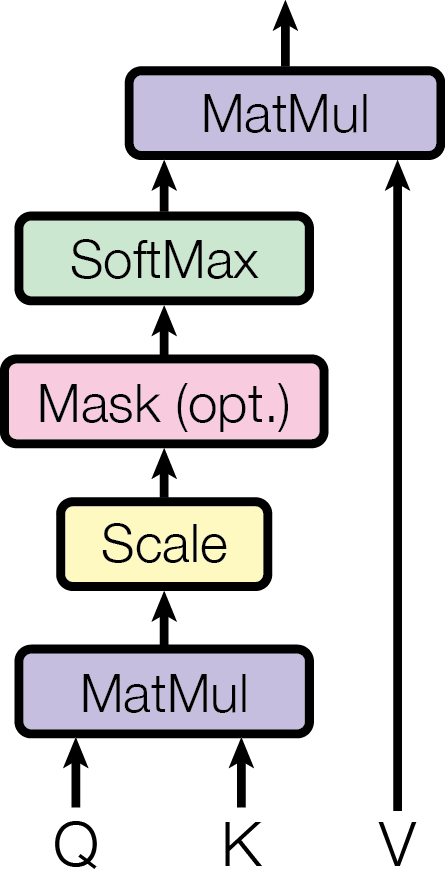

In [15]:
image_requete = next(IMAGE_DIR.glob("page_004_*.png"))
r2 = interroger(f"Que représente l'image {image_requete} et quel est son rôle dans le Transformer ?")

**Interprétation.** L'image fournie est retrouvée avec un score de **1,00** et identifiée comme le **Scaled Dot-Product Attention**, ce qui est correct. La trace montre que le LLM a placé le chemin, déformé (`results_pdf`), dans la requête au lieu de l'argument `chemin_image`. La **correction par le code** a permis la recherche par image : cette réussite ne vient donc pas uniquement de l'agent.

**Point critique :** l'explication du rôle est incomplète, car elle **omet la mise à l'échelle par √dk**.

**Test 3 : question en plusieurs parties**

In [16]:
r3 = interroger("Combien de têtes d'attention le modèle de base utilise-t-il, et quel score BLEU obtient-il de l'anglais vers l'allemand ?")

QUESTION : Combien de têtes d'attention le modèle de base utilise-t-il, et quel score BLEU obtient-il de l'anglais vers l'allemand ?



→ ACTION : retriever_tool {'requetes': ['number of attention heads in base model', 'BLEU score from English to German'], 'type_resultat': 'texte'}
← OBSERVATION : texte p.8 (0.78), texte p.5 (0.77), texte p.4 (0.77), texte p.4 (0.71), texte p.8 (0.69), texte p.8 (0.67), texte p.9 (0.60), texte p.1 (0.58)



RÉPONSE (1 appel(s) d'outil) :


Le modèle de base utilise 8 têtes d'attention (p. 5). Le score BLEU obtenu de l'anglais vers l'allemand est de 27.3 (p. 8).

**Interprétation.** L'agent **décompose** la question en deux requêtes. Les deux réponses sont exactes : **8 têtes** (p. 5) et un score BLEU anglais → allemand de **27,3** pour le modèle de base (p. 8, tableau 2). Pendant la mise au point, l'agent donnait **28,4**, qui est le score du *Transformer (big)*. La correction a nécessité plusieurs changements : meilleure recherche textuelle, extraction conservant les tableaux et consignes plus précises.

**Test 4 : question hors du document** (l'agent ne devrait pas appeler l'outil)

In [17]:
r4 = interroger("Quelle est la capitale du Maroc ?")

QUESTION : Quelle est la capitale du Maroc ?



RÉPONSE (0 appel(s) d'outil) :


La question est hors du document.

**Interprétation.** La question ne concerne pas le document : l'agent répond **sans appeler l'outil** et indique qu'elle est hors du document. Avec le test précédent, cela montre que l'appel à la recherche est une **décision du LLM** et non une étape automatique.

In [18]:
for nom, r in [("test 1", r1), ("test 2", r2), ("test 3", r3), ("test 4", r4)]:
    print(f"{nom} : {len(r['appels'])} appel(s), {len(r['figures'])} figure(s)")

test 1 : 1 appel(s), 2 figure(s)
test 2 : 1 appel(s), 1 figure(s)
test 3 : 1 appel(s), 0 figure(s)
test 4 : 0 appel(s), 0 figure(s)


**Interprétation.**

| Test | Appels | Figures | Comportement vérifié |
|---|---|---|---|
| 1 | 1 | 2 | Recherche hybride texte et figure |
| 2 | 1 | 1 | Requête par image (avec correction du chemin par le code) |
| 3 | 1 (2 requêtes) | 0 | Décomposition de la question |
| 4 | 0 | 0 | Aucune recherche hors sujet |

L'agent adapte son action à la question. Dans ces quatre tests, un seul appel lui a suffi : la **relance d'une recherche** après une observation insuffisante est permise par le graphe, mais n'a pas été observée ici.

## Synthèse et conclusion

### 1. Objectif et démarche

Le but de ce TP est de construire un RAG capable d'exploiter le texte et les figures de l'article *Attention Is All You Need*, puis de le confier à un agent qui décide lui-même quand chercher.

La chaîne est la suivante : **PDF → PyMuPDF → CLIP / mxbai → ChromaDB → `retriever_tool` → agent ReAct (LangGraph)**.

Le projet utilise des modèles locaux via Ollama : `qwen3:8b` pour l'agent et `qwen2.5vl:3b` pour lire les figures. Aucune clé API n'est nécessaire ; en contrepartie, ces modèles de petite taille ont des limites.

L'extraction donne 11 pages et 3 images. L'index CLIP contient 182 fragments de texte et les 3 images ; le second index texte (`mxbai`) contient 46 fragments plus longs.

### 2. Difficultés rencontrées

Un enseignement central du projet : un code qui s'exécute sans erreur ne donne pas forcément de bonnes réponses.

- **Images :** les figures ont un masque de transparence. Il fallait le recombiner avec l'image et ajouter un fond blanc.
- **Limite de CLIP :** il ne lit que 77 tokens, d'où des fragments courts. Cela s'est révélé insuffisant pour retrouver certains passages précis. `mxbai-embed-large` a donc été ajouté pour le texte, en gardant CLIP pour les figures et les requêtes image. Les textes et les images restent aussi dans l'index CLIP commun, comme demandé.
- **Tableaux :** à l'extraction, les valeurs étaient séparées de leurs colonnes. L'option `sort=True` conserve mieux la mise en page.
- **Agent :** il oubliait parfois une partie de la question. L'outil accepte maintenant une requête par sous-question.
- **Chemin d'image :** le LLM pouvait le déformer ou le mettre au mauvais endroit. La correction est assurée par le code et non par l'agent.

### 3. Résultats

Sur 12 questions de comparaison, le bon passage est dans les 5 premiers résultats **12 fois avec `mxbai`, contre 9 avec CLIP**.

| Test de l'agent | Observation |
|---|---|
| Texte et figure | Explication correcte dans l'ensemble, figure 2 retrouvée |
| Requête image | Figure *Scaled Dot-Product Attention* identifiée ; explication incomplète (mise à l'échelle omise) |
| Deux questions | 8 têtes (p. 5) et BLEU anglais → allemand de 27,3 (p. 8) |
| Hors document | L'agent répond sans appeler l'outil |

Le troisième test a d'abord échoué : l'agent donnait le score du *big model* à la place de celui du modèle de base. Une réponse bien rédigée peut donc être fausse, et il vaut mieux la comparer aux passages retrouvés.

### 4. Limites et conclusion

Ces résultats sont encourageants mais à prendre avec prudence : un seul article, peu de questions, et certains réglages ont été faits à partir des tests ci-dessus. Le chiffre de 12/12 ne veut pas dire que la recherche trouvera toujours le bon passage. Le modèle de vision peut aussi inventer des liens entre les blocs d'une figure, la légende du PDF est plus fiable.

Au final, la chaîne demandée est en place, de l'extraction jusqu'à l'agent. Principal enseignement : la qualité de l'extraction et de la recherche compte autant que le choix du LLM. Comme suite, on pourrait tester sur d'autres PDF avec un jeu de questions plus large, ajouter une recherche par mots-clés, puis une interface Streamlit.